# Phase 5B-2 — Imbalance treatments beyond threshold-only policies

HGB and LR, each under Original / Balanced / RandomUnderSampler treatments. Same approved grids, saved development data, nested outer folds and threshold objectives. No SMOTE/SMOTENC, new family, feature ablation, final deployment policy, held-out evaluation or Phase 6. Source: latest fetched main `596d6bc`.

## Colab setup

Upload this notebook, preprocessing.py, 02_cleaned_dataset.csv, 03_split_indices.json, 06_nested_cv_targeting.ipynb, 06_nested_cv_targeting_summary.md and 07_threshold_decision_summary.md; or set PROJECT_DIR to mounted Drive. Standard scientific packages plus imbalanced-learn are required. Tested sklearn=1.8.0, imbalanced-learn=0.14.2, sklearn-compat=0.1.6. If needed, run a separate setup cell `%pip install scikit-learn==1.8.0 imbalanced-learn==0.14.2 sklearn-compat==0.1.6` and restart the runtime before Run all. Local setup installed dependencies in scratch space; project code/data were not overwritten. This runtime writes only the new summary; save the notebook for results. Sequential fitting with bounded native threads can take several minutes.

Review preserved Phase 2C–5B-1 artifacts. Verify the original no-treatment selections were inner-AP choices on each outer-training partition, not outer choices; their approved grids have the same candidate budgets as both new treatment grids. Original-arm pipelines/thresholds are regenerated and must reproduce Phase 5B-1. Reuse avoids 475 duplicate inner fits without giving other arms a different selection budget. Current full experiment: 1,130 fits; no grid reduction based on results.

## 1. Source integrity and development-only loading

Exact cleaned hash binds row order to saved positions. Parser skips all held-out rows. Same original 32,940 development observations, outer folds/checksum and validation prevalence; no new split or encoded matrix. Existing archive code/parameter membership is validated before reuse.


In [1]:
from pathlib import Path
import sys,json,hashlib,warnings,time,ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator,TransformerMixin,clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import ParameterGrid,GridSearchCV
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix
from threadpoolctl import threadpool_limits
from IPython.display import display
import imblearn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
PROJECT_DIR=Path.cwd()
required=['preprocessing.py','02_cleaned_dataset.csv','03_split_indices.json','06_nested_cv_targeting_summary.md','06_nested_cv_targeting.ipynb','07_threshold_decision_summary.md']
if any(not (PROJECT_DIR/n).is_file() for n in required):
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Place the required files in PROJECT_DIR') from exc
    files.upload()
if any(not (PROJECT_DIR/n).is_file() for n in required):raise FileNotFoundError(required)
sys.path.insert(0,str(PROJECT_DIR))
from preprocessing import make_preprocessor,make_cv,FEATURES,CATEGORICAL,NUMERICAL,RECENCY
BASE_MAIN='596d6bc'

def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
input_hashes={n:sha(PROJECT_DIR/n) for n in required}
for n in ['dataset.csv','04_baseline_summary.md','05_model_comparison_summary.md','05b_hist_gradient_boosting_summary.md']:
    if (PROJECT_DIR/n).is_file():input_hashes[n]=sha(PROJECT_DIR/n)
saved=json.loads((PROJECT_DIR/'03_split_indices.json').read_text())
assert input_hashes['02_cleaned_dataset.csv']==saved['input_sha256'] and saved['row_count']==41176
idx=np.asarray(saved['development_indices'],dtype=int);held=np.asarray(saved['held_out_indices'],dtype=int)
assert len(idx)==32940 and len(held)==8236 and len(np.unique(idx))==len(idx) and len(np.unique(held))==len(held)
assert not np.intersect1d(idx,held).size
np.testing.assert_array_equal(np.sort(np.r_[idx,held]),np.arange(41176))
keep=set(idx.tolist())
dev=pd.read_csv(PROJECT_DIR/'02_cleaned_dataset.csv',float_precision='round_trip',skiprows=lambda n:n>0 and n-1 not in keep)
assert dev.shape==(32940,16) and dev.columns.tolist()==FEATURES+['y']
dev.index=np.sort(idx);dev=dev.loc[idx].copy();snapshot=dev.copy(deep=True)
assert not dev.isna().any().any() and dev.y.isin([0,1]).all()
assert np.isfinite(dev[NUMERICAL+RECENCY].to_numpy()).all() and dev.recency_days.between(0,27).all()
assert dev.recency_available.isin([0,1]).all() and dev.loc[dev.recency_available.eq(0),'recency_days'].eq(0).all()
X=dev[FEATURES].copy();y=dev.y.copy();outer_folds=list(make_cv().split(X,y))
for (a,b),(aa,bb) in zip(outer_folds,make_cv().split(X,y)):
    np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
outer_hash=hashlib.sha256(b''.join(idx[b].astype('<i8').tobytes() for _,b in outer_folds)).hexdigest()
assert outer_hash=='6016ca88c4c344724075ade804828d47f03a69bf7337f5287cee0f4a444457c4'
assert all(not np.intersect1d(idx[a],held).size and not np.intersect1d(idx[b],held).size for a,b in outer_folds)
old_text=(PROJECT_DIR/'06_nested_cv_targeting_summary.md').read_text()
oldnb=json.loads((PROJECT_DIR/'06_nested_cv_targeting.ipynb').read_text())
oldcode='\n'.join(''.join(c['source']) for c in oldnb['cells'] if c['cell_type']=='code')
assert 'search.fit(outer_X,outer_y)' in oldcode and 'best_parameters' in oldcode
assert "json.dumps(search.best_params_,sort_keys=True)" in oldcode
assert 'inner_folds=list(make_cv().split(outer_X,outer_y))' in oldcode

def historical_table(heading):
    lines=[]
    for line in old_text.split(heading,1)[1].splitlines():
        if line.startswith('| '):lines.append(line)
        elif lines:break
    assert len(lines)>2
    cols=[a.strip() for a in lines[0].split('|')[1:-1]]
    return pd.DataFrame([[a.strip() for a in l.split('|')[1:-1]] for l in lines[2:]],columns=cols)
old_selections=historical_table('## Fold-specific selected hyperparameters')
old_results=historical_table('## Individual outer-fold predictive results')
old_pooled=historical_table('## Business targeting — pooled nested outer OOF ranks')
old_local_summary=historical_table('Mean and sample SD across the five cohorts')
old_ast=ast.parse(oldcode)
old_grids=ast.literal_eval(next(n.value for n in old_ast.body if isinstance(n,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='GRIDS' for t in n.targets)))
MODELS=['HistGradientBoosting','LogisticRegression']
APPROVED_GRIDS={
 'LogisticRegression':{'classifier__C':[.1,1.,10.]},
 'HistGradientBoosting':{'classifier__learning_rate':[.05,.1],'classifier__max_iter':[100,200],
 'classifier__max_leaf_nodes':[15,31],'classifier__l2_regularization':[0.,1.]}}
for m in MODELS:
    assert old_grids[m]==APPROVED_GRIDS[m]
    assert len(old_selections.loc[old_selections.model.eq(m)])==5
    for s in old_selections.loc[old_selections.model.eq(m),'best_parameters']:
        assert json.loads(s) in list(ParameterGrid(APPROVED_GRIDS[m]))
print('Latest main:',BASE_MAIN,'| exact Phase 5A development/fold hash verified:',outer_hash)
print('No reusable fitted-model/row-prediction artifact was published. Reuse verified training-only parameter selections, not outer-label choices.')
print('Unchanged original-arm selections reused. Both new treatments receive the full approved grids.')




Latest main: 596d6bc | exact Phase 5A development/fold hash verified: 6016ca88c4c344724075ade804828d47f03a69bf7337f5287cee0f4a444457c4
No reusable fitted-model/row-prediction artifact was published. Reuse verified training-only parameter selections, not outer-label choices.
Unchanged original-arm selections reused. Both new treatments receive the full approved grids.


## 2. Compatible preprocessing and treatment pipelines

Imbalanced-learn rejects nested sklearn Pipelines as intermediate steps. Use the fresh ColumnTransformer object extracted from the existing factory (unchanged subcomponents), then stateless finite guard, sampler/passthrough, classifier. Every arm uses this experiment-only adapter; preprocessing.py remains unchanged.

Preprocessing learns from **all raw fitting-fold rows before sampling**, so OHE levels/standard scaling/observed-recency statistics use the same distribution in all arms. Original: weights None/sampler passthrough. Balanced: classifier class_weight='balanced', no sampling; weights are calculated internally per fitting labels. RUS: random_state=42, sampling_strategy='auto', replacement=False, weights None; select whole transformed rows, retain all minority and equal sampled majority rows. No synthetic values. LR keeps approved conditional scaling; HGB remains unscaled with categorical_features=None, early_stopping=False.

Sampler assertions verify target alignment, selected row identity, unique indices, class balancing, fitting-only row sets and unchanged state/no resampling at prediction. Validation always has original full cohort size/prevalence. Audits verify every fitted category/statistic, finite representation and prediction partition.

Same threshold grid/rules as Phase 5B-1: 0.10–0.60 by 0.05, fixed .50, training-OOF F1 max, training-OOF maximum recall subject to illustrative empirical precision >=50%. Deterministic tie rules and no-feasible handling are unchanged. Nonfeasibility means none within this grid; abstention is explicit, not a claim all thresholds fail. Weighted/sampled scores may move useful cutoffs outside this range, but no post-result expansion/calibration is performed.

Optional SMOTENC is assessed but deferred. It would need training-only mixed categorical/numeric representation before final OHE, distance-scaling choices, explicit category flags (including availability), and validation/constraints preserving recency availability and count domains. Ordinary SMOTE on full dummy columns is not implemented.


In [2]:
GRID=np.round(np.arange(.10,.601,.05),2)
assert GRID.tolist()==[.1,.15,.2,.25,.3,.35,.4,.45,.5,.55,.6]
MIN_PRECISION=.50  # illustrative research assumption, not a bank policy
METRICS=['Accuracy','Precision','Recall','F1','ROC_AUC','AP']
POLICIES=['Reference_0.50','Training_F1','Training_Precision50']

def metrics(actual,prob,pred):
    tn,fp,fn,tp=map(int,confusion_matrix(actual,pred,labels=[0,1]).ravel())
    return dict(Accuracy=accuracy_score(actual,pred),Precision=precision_score(actual,pred,zero_division=0),
        Recall=recall_score(actual,pred,zero_division=0),F1=f1_score(actual,pred,zero_division=0),
        ROC_AUC=roc_auc_score(actual,prob),AP=average_precision_score(actual,prob),
        predicted_positives=int(np.sum(pred)),positive_rate=float(np.mean(pred)),TN=tn,FP=fp,FN=fn,TP=tp)

def choose_thresholds(actual,prob):
    assert frozenset(actual.index)==CONTEXT['outer_train_key']
    assert not set(actual.index).intersection(CONTEXT['outer_val_key'])
    assert np.isfinite(prob).all()
    rows=[]
    for t in GRID:
        p=prob>=t
        rows.append({'threshold':float(t),'Precision':precision_score(actual,p,zero_division=0),
            'Recall':recall_score(actual,p,zero_division=0),'F1':f1_score(actual,p,zero_division=0),'predicted_positives':int(p.sum())})
    # Prespecified deterministic rules: maximum F1, ties -> highest threshold.
    f1=max(rows,key=lambda r:(r['F1'],r['threshold']))
    eligible=[r for r in rows if r['predicted_positives']>0 and r['Precision']>=MIN_PRECISION]
    # Precision objective: maximize recall subject to minimum precision; ties -> precision, threshold.
    constrained=max(eligible,key=lambda r:(r['Recall'],r['Precision'],r['threshold'])) if eligible else None
    return {'Reference_0.50':.5,'Training_F1':f1['threshold'],
            'Training_Precision50':constrained['threshold'] if constrained else None},rows

class FiniteGuard(TransformerMixin,BaseEstimator):
    def __init__(self,scaled=False):self.scaled=scaled
    def check(self,z):
        assert isinstance(z,np.ndarray) and np.isfinite(z).all() and np.isin(z[:,:-9],[0.,1.]).all()
        assert np.isin(z[:,-1],[0.,1.]).all() and (z[z[:,-1]==0,-2]==0).all()
        if not self.scaled:assert ((z[:,-2]>=0)&(z[:,-2]<=27)).all()
        return z
    def fit(self,z,y=None):self.check(z);self.n_features_in_=z.shape[1];return self
    def transform(self,z):self.check(z);assert z.shape[1]==self.n_features_in_;return z
    def get_feature_names_out(self,input_features=None):return np.asarray(input_features,dtype=object)

def signature(pre):
    ct=pre;num=ct.named_transformers_['numerical'];rec=ct.named_transformers_['recency']
    sig={'categories':[a.tolist() for a in ct.named_transformers_['categorical'].categories_]}
    if hasattr(num,'mean_'):sig['numeric']=[num.mean_.tolist(),num.var_.tolist(),num.scale_.tolist(),np.asarray(num.n_samples_seen_).tolist()]
    if hasattr(rec,'mean_'):sig['recency']=[rec.mean_,rec.var_,rec.scale_,rec.n_available_]
    return sig
CONTEXT={};FIT_AUDIT=[];PRED_AUDIT=[];WARNING_LOG=[];SAMPLING_AUDIT=[];CURRENT_FIT_ROWS=None
TREATMENTS=['Original','Balanced','RandomUnderSampler']
class AuditedUnderSampler(RandomUnderSampler):
    def fit_resample(self,X,y,**params):
        assert CURRENT_FIT_ROWS is not None and len(X)==len(CURRENT_FIT_ROWS)
        assert np.array_equal(np.asarray(y.index),CURRENT_FIT_ROWS)
        assert not set(CURRENT_FIT_ROWS).intersection(CONTEXT['outer_val_key'])
        assert not set(CURRENT_FIT_ROWS).intersection(held)
        xr,yr=super().fit_resample(X,y,**params)
        ii=self.sample_indices_
        assert len(np.unique(ii))==len(ii)
        np.testing.assert_array_equal(xr,np.asarray(X)[ii])
        np.testing.assert_array_equal(np.asarray(yr),np.asarray(y)[ii])
        before=np.bincount(np.asarray(y,dtype=int),minlength=2);after=np.bincount(np.asarray(yr,dtype=int),minlength=2)
        assert after[0]==after[1]==before.min()
        SAMPLING_AUDIT.append({'model':CONTEXT['model'],'outer_fold':CONTEXT['outer_fold'],
            'role':('outer-training refit' if frozenset(CURRENT_FIT_ROWS)==CONTEXT['outer_train_key'] else CONTEXT['fit_role']),'before_rows':len(X),'after_rows':len(xr),'before_no':int(before[0]),
            'before_yes':int(before[1]),'after_no':int(after[0]),'after_yes':int(after[1]),'status':'PASS'})
        return xr,yr
class AuditedPipeline(ImbPipeline):
    def fit(self,X,y=None,**params):
        global CURRENT_FIT_ROWS
        CURRENT_FIT_ROWS=X.index.to_numpy().copy()
        key=frozenset(X.index)
        assert key in CONTEXT['oof_train_keys'] or key==CONTEXT['outer_train_key']
        assert not key.intersection(CONTEXT['outer_val_key']) and not set(X.index).intersection(held)
        assert np.array_equal(X.index,y.index)
        pre=self.named_steps['preprocessing'];assert not hasattr(pre,'transformers_')
        with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=1):
            warnings.simplefilter('always');result=super().fit(X,y,**params)
        ct=pre;enc=ct.named_transformers_['categorical']
        for c,levels in zip(CATEGORICAL,enc.categories_):np.testing.assert_array_equal(levels,np.sort(X[c].unique()))
        assert enc.drop is None and enc.handle_unknown=='ignore'
        num=ct.named_transformers_['numerical'];rec=ct.named_transformers_['recency']
        if CONTEXT['model']=='LogisticRegression':
            np.testing.assert_allclose(num.mean_,X[NUMERICAL].mean(),rtol=1e-12,atol=1e-12)
            np.testing.assert_allclose(num.var_,X[NUMERICAL].var(ddof=0),rtol=1e-12,atol=1e-12)
            sd=np.sqrt(X[NUMERICAL].var(ddof=0).to_numpy());sd[sd==0]=1
            np.testing.assert_allclose(num.scale_,sd,rtol=1e-12,atol=1e-12)
            assert np.all(np.asarray(num.n_samples_seen_)==len(X))
            observed=X.loc[X.recency_available.eq(1),'recency_days'].to_numpy()
            mean=observed.mean() if len(observed) else 0.;var=observed.var(ddof=0) if len(observed) else 0.;sd=np.sqrt(var) if var>0 else 1.
            assert rec.n_available_==len(observed)
            np.testing.assert_allclose([rec.mean_,rec.var_,rec.scale_],[mean,var,sd],rtol=1e-12)
        else:
            assert not hasattr(num,'mean_') and not hasattr(rec,'mean_')
        clf=self.named_steps['classifier'];np.testing.assert_array_equal(clf.classes_,[0,1])
        assert clf.class_weight==('balanced' if CONTEXT['treatment']=='Balanced' else None) and clf.random_state==42
        if hasattr(clf,'coef_'):assert np.isfinite(clf.coef_).all() and np.isfinite(clf.intercept_).all()
        if CONTEXT['model']=='HistGradientBoosting':
            assert clf.categorical_features is None and clf.early_stopping is False and clf.n_iter_==clf.max_iter
        self._fit_rows=key
        role='outer-training refit' if key==CONTEXT['outer_train_key'] else CONTEXT['fit_role']
        for w in caught:WARNING_LOG.append({'model':CONTEXT['model'],'treatment':CONTEXT['treatment'],'outer_fold':CONTEXT['outer_fold'],'role':role,'category':w.category.__name__,'message':str(w.message)})
        FIT_AUDIT.append({'model':CONTEXT['model'],'treatment':CONTEXT['treatment'],'outer_fold':CONTEXT['outer_fold'],'role':role,'rows':len(X),'warnings':len(caught),'status':'PASS'})
        return result
    def predict_proba(self,X,**params):
        key=frozenset(X.index);assert not key.intersection(self._fit_rows)
        if CONTEXT['role'] in ['inner validation','training-side OOF']:assert key in CONTEXT['oof_val_keys'] and not key.intersection(CONTEXT['outer_val_key'])
        else:assert CONTEXT['role']=='outer validation' and CONTEXT['thresholds_frozen'] and key==CONTEXT['outer_val_key']
        assert not set(X.index).intersection(held)
        before_sampling=len(SAMPLING_AUDIT)
        sampler=self.named_steps['sampler']
        sample_state=sampler.sample_indices_.copy() if hasattr(sampler,'sample_indices_') else None
        pre=self.named_steps['preprocessing'];before=signature(pre);z=pre.transform(X);self.named_steps['finite_guard'].transform(z)
        np.testing.assert_array_equal(z[:,-1],X.recency_available)
        rec=pre.named_transformers_['recency']
        if hasattr(rec,'mean_'):
            mask=X.recency_available.eq(1).to_numpy()
            np.testing.assert_allclose(z[mask,-2],(X.loc[mask,'recency_days']-rec.mean_)/rec.scale_)
        else:np.testing.assert_array_equal(z[:,-9:],X[NUMERICAL+RECENCY].to_numpy())
        with threadpool_limits(limits=1):out=super().predict_proba(X,**params)
        assert len(SAMPLING_AUDIT)==before_sampling and len(out)==len(X)
        if sample_state is not None:np.testing.assert_array_equal(sampler.sample_indices_,sample_state)
        assert signature(pre)==before and np.isfinite(out).all() and ((out>=0)&(out<=1)).all()
        PRED_AUDIT.append({'model':CONTEXT['model'],'treatment':CONTEXT['treatment'],'outer_fold':CONTEXT['outer_fold'],'role':CONTEXT['role'],'rows':len(X),'status':'PASS'})
        return out

def factory(model,treatment,params=None):
    if model=='LogisticRegression':
        name='logistic_regression';clf=LogisticRegression(C=1.,max_iter=1000,solver='lbfgs',random_state=42,class_weight=None)
    elif model=='HistGradientBoosting':
        name='decision_tree';clf=HistGradientBoostingClassifier(learning_rate=.1,max_iter=100,max_leaf_nodes=31,
            l2_regularization=0.,early_stopping=False,random_state=42,class_weight=None,categorical_features=None)
    else:raise ValueError(model)
    clf.set_params(class_weight='balanced' if treatment=='Balanced' else None)
    fresh_ct=make_preprocessor(name).named_steps['preprocessor']
    sampler=AuditedUnderSampler(sampling_strategy='auto',replacement=False,random_state=42) if treatment=='RandomUnderSampler' else 'passthrough'
    p=AuditedPipeline([('preprocessing',fresh_ct),('finite_guard',FiniteGuard(scaled=model=='LogisticRegression')),('sampler',sampler),('classifier',clf)])
    return p.set_params(**(params or {}))
# Explicit policy-selector tests use only synthetic examples, not outer labels.
_test_key=frozenset(range(4));CONTEXT.update(outer_train_key=_test_key,outer_val_key=frozenset([999999]))
a=pd.Series([1,0,1,0],index=range(4));prob=np.array([.01,.02,.03,.04])
chosen,table=choose_thresholds(a,prob)
assert chosen['Training_Precision50'] is None  # no positive selection can reach the minimum
assert chosen['Training_F1']==.6  # all F1=0; highest-threshold tie-break
chosen2,_=choose_thresholds(a,prob);assert chosen==chosen2
print('Predeclared threshold grid/rules and no-feasible-candidate behavior validated.')


for model in MODELS:
    for treatment in TREATMENTS:clone(factory(model,treatment))
def inner_score(est,data,actual):
    assert CONTEXT['role']=='inner validation'
    prob=est.predict_proba(data)[:,list(est.classes_).index(1)]
    from sklearn.metrics import average_precision_score
    return {'AP':average_precision_score(actual,prob)}


Predeclared threshold grid/rules and no-feasible-candidate behavior validated.


## 3. Nested treatment selection and frozen policies

Within every outer-training partition, identical inner folds/grid settings/positive-probability AP select each new treatment's hyperparameters. Original archived selections use the same grids and training data. Winners refit outer training; selected-model cross-fitting generates training-side OOF probabilities for thresholds. These scores are conditional on hyperparameters chosen using all outer-training labels: selection data, not independent inner performance. Only frozen policies are evaluated on outer validation.

Every new search clones a complete preprocessing/sampling/classifier pipeline. RUS is fit_resample inside each training fit, never on validation. No full-development preprocessing or model fit. Three policy decisions share each outer probability; threshold changes cannot change AP/ROC-AUC. Reproduce all no-treatment reference policy scores, thresholds and volumes before accepting results. Fair model-selection budgets: LR 3 candidates and HGB 16 for every arm; no weight/sampler-ratio tuning added.


In [3]:
started=time.perf_counter();policy_rows=[];threshold_rows=[];selection_rows=[];cost_rows=[];candidate_rows=[];oof={}
for model in MODELS:
    for treatment in TREATMENTS:oof[(model,treatment)]={'prob':np.full(len(X),np.nan),'coverage':np.zeros(len(X),int),'pred':{p:np.full(len(X),-1,int) for p in POLICIES}}
for outer_fold,(otr,ova) in enumerate(outer_folds,start=1):
    train_X=X.iloc[otr];train_y=y.iloc[otr];training_folds=list(make_cv().split(train_X,train_y))
    for (a,b),(aa,bb) in zip(training_folds,make_cv().split(train_X,train_y)):
        np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
    for model in MODELS:
        for treatment in TREATMENTS:
            CONTEXT.update(model=model,treatment=treatment,outer_fold=outer_fold,outer_train_key=frozenset(train_X.index),outer_val_key=frozenset(X.iloc[ova].index),
                oof_train_keys={frozenset(train_X.iloc[a].index) for a,b in training_folds},oof_val_keys={frozenset(train_X.iloc[b].index) for a,b in training_folds},
                role='inner validation',fit_role='inner search',thresholds_frozen=False)
            t=time.perf_counter();grid_seconds=0.;new_search_fits=0
            if treatment=='Original':
                record=old_selections.loc[old_selections.model.eq(model)&old_selections.outer_fold.eq(str(outer_fold))].iloc[0]
                params=json.loads(record.best_parameters);best_estimator=None
                selection_source='reused exact Phase 5A training-only inner AP selection'
            else:
                g=GridSearchCV(factory(model,treatment),APPROVED_GRIDS[model],scoring=inner_score,refit='AP',cv=training_folds,
                    n_jobs=1,error_score='raise',return_train_score=False)
                before=len(FIT_AUDIT);g.fit(train_X,train_y);grid_seconds=time.perf_counter()-t
                new_search_fits=5*len(ParameterGrid(APPROVED_GRIDS[model]))
                assert len(FIT_AUDIT)-before==new_search_fits+1
                params=g.best_params_;best_estimator=g.best_estimator_
                assert np.isfinite(g.cv_results_['mean_test_AP']).all()
                selection_source='fresh outer-training-only inner AP search'
                for i,par in enumerate(g.cv_results_['params']):
                    vals=np.asarray([g.cv_results_[f'split{j}_test_AP'][i] for j in range(5)])
                    assert np.isfinite(vals).all()
                    candidate_rows.append({'model':model,'treatment':treatment,'outer_fold':outer_fold,'parameters':json.dumps(par,sort_keys=True),
                        'inner_AP_mean':vals.mean(),'inner_AP_SD':vals.std(ddof=1),'rank_AP':int(g.cv_results_['rank_test_AP'][i])})
            assert params in list(ParameterGrid(APPROVED_GRIDS[model]))
            selection_rows.append({'model':model,'treatment':treatment,'outer_fold':outer_fold,'parameters':json.dumps(params,sort_keys=True),'source':selection_source})
            CONTEXT.update(role='training-side OOF',fit_role='training-side OOF fit')
            train_prob=np.full(len(train_X),np.nan);coverage=np.zeros(len(train_X),int)
            for a,b in training_folds:
                est=factory(model,treatment,params);est.fit(train_X.iloc[a],train_y.iloc[a])
                train_prob[b]=est.predict_proba(train_X.iloc[b])[:,list(est.classes_).index(1)];coverage[b]+=1
            assert (coverage==1).all() and np.isfinite(train_prob).all()
            chosen,selection_table=choose_thresholds(train_y,train_prob);repeated,_=choose_thresholds(train_y,train_prob)
            assert chosen==repeated
            frozen=dict(chosen);CONTEXT['thresholds_frozen']=True
            for policy,threshold in chosen.items():
                training_row=next((r for r in selection_table if r['threshold']==threshold),None)
                threshold_rows.append({'model':model,'treatment':treatment,'outer_fold':outer_fold,'policy':policy,
                    'threshold':threshold if threshold is not None else 'none feasible','training_feasible':threshold is not None,
                    'training_precision':training_row['Precision'] if training_row else 'not applicable',
                    'training_recall':training_row['Recall'] if training_row else 'not applicable'})
            if best_estimator is None:
                best_estimator=factory(model,treatment,params);best_estimator.fit(train_X,train_y)
            CONTEXT['role']='outer validation'
            prob=best_estimator.predict_proba(X.iloc[ova])[:,list(best_estimator.classes_).index(1)]
            assert chosen==frozen
            actual=y.iloc[ova];output=oof[(model,treatment)]
            assert (output['coverage'][ova]==0).all()
            output['prob'][ova]=prob;output['coverage'][ova]+=1
            for policy,threshold in frozen.items():
                pred=(prob>=threshold).astype(int) if threshold is not None else np.zeros(len(ova),int)
                output['pred'][policy][ova]=pred
                policy_rows.append({'model':model,'treatment':treatment,'outer_fold':outer_fold,'policy':policy,**metrics(actual,prob,pred)})
            cost_rows.append({'model':model,'treatment':treatment,'outer_fold':outer_fold,
                'candidates_in_selection_budget':len(ParameterGrid(APPROVED_GRIDS[model])),
                'new_inner_search_fits':new_search_fits,'threshold_OOF_fits':5,'outer_refits':1,
                'grid_refit_seconds':grid_seconds,'total_seconds':time.perf_counter()-t})
            print(f'Outer {outer_fold}/5 {model} {treatment}: AP={policy_rows[-1]["AP"]:.6f}; thresholds={frozen}; seconds={cost_rows[-1]["total_seconds"]:.1f}',flush=True)
for key,output in oof.items():
    assert (output['coverage']==1).all() and np.isfinite(output['prob']).all()
    for policy in POLICIES:assert np.isin(output['pred'][policy],[0,1]).all()
assert len(FIT_AUDIT)==1130 and len(PRED_AUDIT)==1130
assert len(SAMPLING_AUDIT)==535
policy_results=pd.DataFrame(policy_rows);thresholds=pd.DataFrame(threshold_rows);selections=pd.DataFrame(selection_rows);cost=pd.DataFrame(cost_rows)
assert np.isfinite(policy_results[METRICS+['predicted_positives','positive_rate','TN','FP','FN','TP']].to_numpy()).all()
assert policy_results.groupby(['model','treatment','outer_fold']).AP.nunique().eq(1).all()
assert policy_results.groupby(['model','treatment','outer_fold']).ROC_AUC.nunique().eq(1).all()
# Verify the original arm exactly reproduces all published Phase 5B-1 outer policy scores and thresholds.
reference_text=(PROJECT_DIR/'07_threshold_decision_summary.md').read_text()
def reference_table(heading):
    lines=[]
    for line in reference_text.split(heading,1)[1].splitlines():
        if line.startswith('| '):lines.append(line)
        elif lines:break
    return pd.DataFrame([[v.strip() for v in row.split('|')[1:-1]] for row in lines[2:]],columns=[v.strip() for v in lines[0].split('|')[1:-1]])
reference=reference_table('## Proper outer-validation policy results')
reference_thresholds=reference_table('## Selected thresholds and stability')
for _,row in policy_results.loc[policy_results.treatment.eq('Original')].iterrows():
    r=reference.loc[reference.model.eq(row.model)&reference.outer_fold.eq(str(row.outer_fold))&reference.policy.eq(row.policy)].iloc[0]
    np.testing.assert_allclose(row[METRICS].astype(float),r[METRICS].astype(float),rtol=0,atol=5.1e-7)
    assert row.predicted_positives==int(r.predicted_positives)
for _,row in thresholds.loc[thresholds.treatment.eq('Original')].iterrows():
    r=reference_thresholds.loc[reference_thresholds.model.eq(row.model)&reference_thresholds.outer_fold.eq(str(row.outer_fold))&reference_thresholds.policy.eq(row.policy)].iloc[0]
    assert float(row.threshold)==float(r.threshold)
print('All 30 original-arm policy-fold scores and thresholds reproduced Phase 5B-1.')
display(policy_results);display(thresholds);display(selections)



Outer 1/5 HistGradientBoosting Original: AP=0.450109; thresholds={'Reference_0.50': 0.5, 'Training_F1': 0.2, 'Training_Precision50': 0.35}; seconds=4.3
Outer 1/5 HistGradientBoosting Balanced: AP=0.450972; thresholds={'Reference_0.50': 0.5, 'Training_F1': 0.6, 'Training_Precision50': None}; seconds=82.4
Outer 1/5 HistGradientBoosting RandomUnderSampler: AP=0.430358; thresholds={'Reference_0.50': 0.5, 'Training_F1': 0.6, 'Training_Precision50': None}; seconds=36.6
Outer 1/5 LogisticRegression Original: AP=0.432797; thresholds={'Reference_0.50': 0.5, 'Training_F1': 0.2, 'Training_Precision50': 0.35}; seconds=0.9
Outer 1/5 LogisticRegression Balanced: AP=0.430936; thresholds={'Reference_0.50': 0.5, 'Training_F1': 0.6, 'Training_Precision50': None}; seconds=2.6
Outer 1/5 LogisticRegression RandomUnderSampler: AP=0.424591; thresholds={'Reference_0.50': 0.5, 'Training_F1': 0.6, 'Training_Precision50': None}; seconds=1.9
Outer 2/5 HistGradientBoosting Original: AP=0.442077; thresholds={'Refer

,model,treatment,outer_fold,policy,Accuracy,Precision,Recall,F1,ROC_AUC,AP,predicted_positives,positive_rate,TN,FP,FN,TP
0,HistGradientBoosting,Original,1,Reference_0.50,0.899666,0.650558,0.235849,0.346192,0.810998,0.450109,269,0.040832,5752,94,567,175
1,HistGradientBoosting,Original,1,Training_F1,0.867183,0.435749,0.607817,0.507597,0.810998,0.450109,1035,0.157104,5262,584,291,451
2,HistGradientBoosting,Original,1,Training_Precision50,0.891621,0.525547,0.388140,0.446512,0.810998,0.450109,548,0.083182,5586,260,454,288
3,HistGradientBoosting,Balanced,1,Reference_0.50,0.844566,0.385366,0.638814,0.480730,0.812087,0.450972,1230,0.186703,5090,756,268,474
4,HistGradientBoosting,Balanced,1,Training_F1,0.863236,0.424787,0.605121,0.499166,0.812087,0.450972,1057,0.160443,5238,608,293,449
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,LogisticRegression,Balanced,5,Training_F1,0.847298,0.382694,0.577389,0.460300,0.765788,0.430457,1121,0.170158,5153,692,314,429
86,LogisticRegression,Balanced,5,Training_Precision50,0.887219,0.000000,0.000000,0.000000,0.765788,0.430457,0,0.000000,5845,0,743,0
87,LogisticRegression,RandomUnderSampler,5,Reference_0.50,0.755313,0.268019,0.675639,0.383792,0.765082,0.429917,1873,0.284305,4474,1371,241,502
88,LogisticRegression,RandomUnderSampler,5,Training_F1,0.840771,0.369898,0.585464,0.453361,0.765082,0.429917,1176,0.178506,5104,741,308,435


,model,treatment,outer_fold,policy,threshold,training_feasible,training_precision,training_recall
0,HistGradientBoosting,Original,1,Reference_0.50,0.5,True,0.660063,0.213203
1,HistGradientBoosting,Original,1,Training_F1,0.2,True,0.429076,0.572583
2,HistGradientBoosting,Original,1,Training_Precision50,0.35,True,0.527404,0.369485
3,HistGradientBoosting,Balanced,1,Reference_0.50,0.5,True,0.375489,0.614011
4,HistGradientBoosting,Balanced,1,Training_F1,0.6,True,0.42207,0.581004
...,...,...,...,...,...,...,...,...
85,LogisticRegression,Balanced,5,Training_F1,0.6,True,0.371647,0.574124
86,LogisticRegression,Balanced,5,Training_Precision50,none feasible,False,not applicable,not applicable
87,LogisticRegression,RandomUnderSampler,5,Reference_0.50,0.5,True,0.265181,0.685647
88,LogisticRegression,RandomUnderSampler,5,Training_F1,0.6,True,0.356852,0.591307


,model,treatment,outer_fold,parameters,source
0,HistGradientBoosting,Original,1,"{""classifier__l2_regularization"": 0.0, ""classi...",reused exact Phase 5A training-only inner AP s...
1,HistGradientBoosting,Balanced,1,"{""classifier__l2_regularization"": 0.0, ""classi...",fresh outer-training-only inner AP search
2,HistGradientBoosting,RandomUnderSampler,1,"{""classifier__l2_regularization"": 0.0, ""classi...",fresh outer-training-only inner AP search
3,LogisticRegression,Original,1,"{""classifier__C"": 0.1}",reused exact Phase 5A training-only inner AP s...
4,LogisticRegression,Balanced,1,"{""classifier__C"": 0.1}",fresh outer-training-only inner AP search
5,LogisticRegression,RandomUnderSampler,1,"{""classifier__C"": 0.1}",fresh outer-training-only inner AP search
6,HistGradientBoosting,Original,2,"{""classifier__l2_regularization"": 1.0, ""classi...",reused exact Phase 5A training-only inner AP s...
7,HistGradientBoosting,Balanced,2,"{""classifier__l2_regularization"": 0.0, ""classi...",fresh outer-training-only inner AP search
8,HistGradientBoosting,RandomUnderSampler,2,"{""classifier__l2_regularization"": 1.0, ""classi...",fresh outer-training-only inner AP search
9,LogisticRegression,Original,2,"{""classifier__C"": 0.1}",reused exact Phase 5A training-only inner AP s...


## 4. Ranking versus decision metrics and equal-K comparisons

Display 90 individual model/treatment/policy/fold records, means/sample SD, pooled confusion counts, threshold stability and grid feasibility. Compare each treatment with threshold-only policies, not only .50. AP/ROC-AUC measure ranking changes; recall shifts at a probability cutoff can come from altered score/prior scales rather than improved ranking.

Use nested outer probabilities at exactly top 5/10/20% with ceil rounding and saved-row position tie-breaking independent of outcomes. Every model/treatment has equal capacity within a cohort. Show pooled and fold-local targeting and additional historical capture versus original HGB at the same pooled K. Pooled scores combine separately fitted models/calibrations; historical capture is not causal call impact or known profit. No best outer threshold is selected from these tables.


In [4]:
means=policy_results.groupby(['model','treatment','policy'])[METRICS+['predicted_positives','positive_rate']].mean()
sds=policy_results.groupby(['model','treatment','policy'])[METRICS+['predicted_positives','positive_rate']].std(ddof=1)
comparison=pd.DataFrame(index=means.index)
for metric in METRICS+['predicted_positives','positive_rate']:
    comparison[metric+' mean ± SD']=[f'{means.loc[i,metric]:.6f} ± {sds.loc[i,metric]:.6f}' for i in means.index]
ranking=policy_results.loc[policy_results.policy.eq('Reference_0.50')].groupby(['model','treatment'])[['AP','ROC_AUC']].agg(['mean','std']).reset_index()
ranking.columns=['model','treatment','AP_mean','AP_SD','ROC_AUC_mean','ROC_AUC_SD']
pooled_policies=pd.DataFrame([{'model':model,'treatment':treatment,'policy':policy,**metrics(y,oof[(model,treatment)]['prob'],oof[(model,treatment)]['pred'][policy])}
    for model in MODELS for treatment in TREATMENTS for policy in POLICIES])
stability=thresholds.groupby(['model','treatment','policy','threshold'],dropna=False).size().rename('fold_count').reset_index()
infeasible=thresholds.loc[thresholds.policy.eq('Training_Precision50')].groupby(['model','treatment']).training_feasible.agg(['sum','size']).reset_index()
infeasible.columns=['model','treatment','feasible_training_folds','outer_folds']
capacity=[];local_capacity=[]
def topk(actual,prob,fraction,ties):
    k=int(np.ceil(len(actual)*fraction));order=np.lexsort((np.asarray(ties),-np.asarray(prob)))
    captured=int(np.asarray(actual)[order[:k]].sum());total=int(np.asarray(actual).sum());precision=captured/k
    return dict(contacts=k,captured_subscribers=captured,Precision_at_K=precision,Recall_at_K=captured/total,Lift_at_K=precision/(total/len(actual)))
for model in MODELS:
    for treatment in TREATMENTS:
        prob=oof[(model,treatment)]['prob']
        for f in [.05,.1,.2]:
            capacity.append({'model':model,'treatment':treatment,'fraction':f,**topk(y,prob,f,X.index)})
            for fold,(_,va) in enumerate(outer_folds,start=1):local_capacity.append({'model':model,'treatment':treatment,'fraction':f,'outer_fold':fold,
                **topk(y.iloc[va],prob[va],f,X.iloc[va].index)})
capacity=pd.DataFrame(capacity);local_capacity=pd.DataFrame(local_capacity)
assert capacity.groupby('fraction').contacts.nunique().eq(1).all()
assert local_capacity.groupby(['fraction','outer_fold']).contacts.nunique().eq(1).all()
local_summary=local_capacity.groupby(['model','treatment','fraction'])[['captured_subscribers','Precision_at_K','Recall_at_K','Lift_at_K']].agg(['mean','std']).reset_index()
local_summary.columns=['model','treatment','fraction','captured_mean','captured_SD','Precision_mean','Precision_SD','Recall_mean','Recall_SD','Lift_mean','Lift_SD']
reference_hgb=capacity.loc[capacity.model.eq('HistGradientBoosting')&capacity.treatment.eq('Original')].set_index('fraction').captured_subscribers
capacity['capture_minus_original_HGB']=capacity.captured_subscribers-capacity.fraction.map(reference_hgb)
fit_summary=pd.DataFrame(FIT_AUDIT).groupby(['model','treatment','role','rows']).size().rename('fits').reset_index()
sampling=pd.DataFrame(SAMPLING_AUDIT)
sampling_summary=sampling.groupby(['model','outer_fold','role'])[['before_rows','after_rows','before_no','before_yes','after_no','after_yes']].agg(['min','max']).reset_index()
sampling_summary.columns=['_'.join(str(v) for v in c if v!='') if isinstance(c,tuple) else c for c in sampling_summary.columns]
cost_summary=cost.groupby(['model','treatment']).agg(selection_candidates=('candidates_in_selection_budget','first'),new_inner_search_fits=('new_inner_search_fits','sum'),
    threshold_OOF_fits=('threshold_OOF_fits','sum'),outer_refits=('outer_refits','sum'),wall_seconds=('total_seconds','sum'))
display(comparison);display(ranking);display(capacity);display(local_summary);display(infeasible);display(stability)
display(fit_summary);display(sampling_summary);display(cost_summary)



Accuracy mean ± SD  ... positive_rate mean ± SD
model                treatment          policy                                     ...                        
HistGradientBoosting Balanced           Reference_0.50        0.843868 ± 0.004728  ...     0.183971 ± 0.003289
                                        Training_F1           0.862872 ± 0.004590  ...     0.157256 ± 0.003498
                                        Training_Precision50  0.887341 ± 0.000068  ...     0.000000 ± 0.000000
                     Original           Reference_0.50        0.899666 ± 0.000387  ...     0.036976 ± 0.003314
                                        Training_F1           0.865270 ± 0.004506  ...     0.154250 ± 0.005088
                                        Training_Precision50  0.891682 ± 0.002083  ...     0.081208 ± 0.003684
                     RandomUnderSampler Reference_0.50        0.835762 ± 0.004164  ...     0.192866 ± 0.007878
                                        Training_F1           0.860504 ± 0.004784  ...     0.160595 ± 0.005016
                                        Training_Precision50  0.887341 ± 0.000068  ...     0.000000 ± 0.000000
LogisticRegression   Balanced           Reference_0.50        0.765786 ± 0.008200  ...     0.274499 ± 0.005764
                                        Training_F1           0.848543 ± 0.006429  ...     0.166485 ± 0.003395
                                        Training_Precision50  0.887341 ± 0.000068  ...     0.000000 ± 0.000000
                     Original           Reference_0.50        0.899180 ± 0.001207  ...     0.031815 ± 0.002083
                                        Training_F1           0.871554 ± 0.003530  ...     0.128476 ± 0.003721
                                        Training_Precision50  0.891651 ± 0.002716  ...     0.070067 ± 0.003342
                     RandomUnderSampler Reference_0.50        0.758136 ± 0.005758  ...     0.282757 ± 0.003705
                                        Training_F1           0.842380 ± 0.001426  ...     0.174833 ± 0.007668
                                        Training_Precision50  0.887341 ± 0.000068  ...     0.000000 ± 0.000000

[18 rows x 8 columns]

,model,treatment,AP_mean,AP_SD,ROC_AUC_mean,ROC_AUC_SD
0,HistGradientBoosting,Balanced,0.450883,0.015341,0.795498,0.011681
1,HistGradientBoosting,Original,0.448145,0.014219,0.794911,0.011816
2,HistGradientBoosting,RandomUnderSampler,0.436259,0.019079,0.792286,0.010668
3,LogisticRegression,Balanced,0.420526,0.011461,0.763275,0.012586
4,LogisticRegression,Original,0.422429,0.011606,0.761875,0.012192
5,LogisticRegression,RandomUnderSampler,0.419671,0.012471,0.762635,0.013194


,model,treatment,fraction,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K,capture_minus_original_HGB
0,HistGradientBoosting,Original,0.05,1647,1005,0.610200,0.270816,5.416330,0
1,HistGradientBoosting,Original,0.10,3294,1628,0.494232,0.438696,4.386958,0
2,HistGradientBoosting,Original,0.20,6588,2377,0.360808,0.640528,3.202641,0
3,HistGradientBoosting,Balanced,0.05,1647,1018,0.618094,0.274320,5.486392,13
4,HistGradientBoosting,Balanced,0.10,3294,1610,0.488767,0.433845,4.338453,-18
5,HistGradientBoosting,Balanced,0.20,6588,2371,0.359897,0.638911,3.194557,-6
6,HistGradientBoosting,RandomUnderSampler,0.05,1647,988,0.599879,0.266236,5.324710,-17
7,HistGradientBoosting,RandomUnderSampler,0.10,3294,1578,0.479053,0.425222,4.252223,-50
8,HistGradientBoosting,RandomUnderSampler,0.20,6588,2348,0.356406,0.632714,3.163568,-29
9,LogisticRegression,Original,0.05,1647,962,0.584092,0.259229,5.184586,-43


,model,treatment,fraction,captured_mean,captured_SD,Precision_mean,Precision_SD,Recall_mean,Recall_SD,Lift_mean,Lift_SD
0,HistGradientBoosting,Balanced,0.05,205.0,2.738613,0.621212,0.008299,0.276205,0.003626,5.514061,0.072379
1,HistGradientBoosting,Balanced,0.10,322.0,11.510864,0.488619,0.017467,0.433844,0.015464,4.337123,0.154594
2,HistGradientBoosting,Balanced,0.20,474.2,10.917875,0.359788,0.008284,0.638912,0.014743,3.193590,0.073691
3,HistGradientBoosting,Original,0.05,202.0,2.000000,0.612121,0.006061,0.272164,0.002745,5.433389,0.054809
4,HistGradientBoosting,Original,0.10,325.4,6.503845,0.493778,0.009869,0.438425,0.008686,4.382921,0.086838
5,HistGradientBoosting,Original,0.20,474.2,14.272351,0.359788,0.010829,0.638912,0.019242,3.193588,0.096180
6,HistGradientBoosting,RandomUnderSampler,0.05,197.4,7.602631,0.598182,0.023038,0.265964,0.010192,5.309618,0.203467
7,HistGradientBoosting,RandomUnderSampler,0.10,317.2,16.991174,0.481335,0.025783,0.427374,0.022788,4.272438,0.227808
8,HistGradientBoosting,RandomUnderSampler,0.20,469.4,12.033287,0.356146,0.009130,0.632444,0.016229,3.161262,0.081120
9,LogisticRegression,Balanced,0.05,192.4,10.597169,0.583030,0.032113,0.259226,0.014200,5.175092,0.283476


,model,treatment,feasible_training_folds,outer_folds
0,HistGradientBoosting,Balanced,0,5
1,HistGradientBoosting,Original,5,5
2,HistGradientBoosting,RandomUnderSampler,0,5
3,LogisticRegression,Balanced,0,5
4,LogisticRegression,Original,5,5
5,LogisticRegression,RandomUnderSampler,0,5


,model,treatment,policy,threshold,fold_count
0,HistGradientBoosting,Balanced,Reference_0.50,0.5,5
1,HistGradientBoosting,Balanced,Training_F1,0.6,5
2,HistGradientBoosting,Balanced,Training_Precision50,none feasible,5
3,HistGradientBoosting,Original,Reference_0.50,0.5,5
4,HistGradientBoosting,Original,Training_F1,0.15,1
5,HistGradientBoosting,Original,Training_F1,0.2,4
6,HistGradientBoosting,Original,Training_Precision50,0.35,5
7,HistGradientBoosting,RandomUnderSampler,Reference_0.50,0.5,5
8,HistGradientBoosting,RandomUnderSampler,Training_F1,0.6,5
9,HistGradientBoosting,RandomUnderSampler,Training_Precision50,none feasible,5


,model,treatment,role,rows,fits
0,HistGradientBoosting,Balanced,inner search,21081,160
1,HistGradientBoosting,Balanced,inner search,21082,240
2,HistGradientBoosting,Balanced,outer-training refit,26352,5
3,HistGradientBoosting,Balanced,training-side OOF fit,21081,10
4,HistGradientBoosting,Balanced,training-side OOF fit,21082,15
5,HistGradientBoosting,Original,outer-training refit,26352,5
6,HistGradientBoosting,Original,training-side OOF fit,21081,10
7,HistGradientBoosting,Original,training-side OOF fit,21082,15
8,HistGradientBoosting,RandomUnderSampler,inner search,21081,160
9,HistGradientBoosting,RandomUnderSampler,inner search,21082,240


,model,outer_fold,role,before_rows_min,before_rows_max,after_rows_min,after_rows_max,before_no_min,before_no_max,before_yes_min,before_yes_max,after_no_min,after_no_max,after_yes_min,after_yes_max
0,HistGradientBoosting,1,inner search,21081,21082,4750,4752,18706,18707,2375,2376,2375,2376,2375,2376
1,HistGradientBoosting,1,outer-training refit,26352,26352,5938,5938,23383,23383,2969,2969,2969,2969,2969,2969
2,HistGradientBoosting,1,training-side OOF fit,21081,21082,4750,4752,18706,18707,2375,2376,2375,2376,2375,2376
3,HistGradientBoosting,2,inner search,21081,21082,4750,4752,18706,18707,2375,2376,2375,2376,2375,2376
4,HistGradientBoosting,2,outer-training refit,26352,26352,5938,5938,23383,23383,2969,2969,2969,2969,2969,2969
5,HistGradientBoosting,2,training-side OOF fit,21081,21082,4750,4752,18706,18707,2375,2376,2375,2376,2375,2376
6,HistGradientBoosting,3,inner search,21081,21082,4750,4752,18706,18707,2375,2376,2375,2376,2375,2376
7,HistGradientBoosting,3,outer-training refit,26352,26352,5938,5938,23383,23383,2969,2969,2969,2969,2969,2969
8,HistGradientBoosting,3,training-side OOF fit,21081,21082,4750,4752,18706,18707,2375,2376,2375,2376,2375,2376
9,HistGradientBoosting,4,inner search,21081,21082,4750,4752,18706,18707,2375,2376,2375,2376,2375,2376


selection_candidates  ...  wall_seconds
model                treatment                                 ...              
HistGradientBoosting Balanced                              16  ...    420.448172
                     Original                              16  ...     21.425863
                     RandomUnderSampler                    16  ...    179.910852
LogisticRegression   Balanced                               3  ...     13.467524
                     Original                               3  ...      4.395567
                     RandomUnderSampler                     3  ...     10.147452

[6 rows x 5 columns]

## 5. Development-only comparison figures

Ranking plot uses outer AP with descriptive sample SD. Targeting plots compare precision/recall/lift at equal capacity. Frozen-policy precision/recall points are decision effects, not altered AP. The illustrative 50% target is not a bank requirement or guaranteed future precision. Weighting/RUS can help or hurt; complexity is not justification by itself.


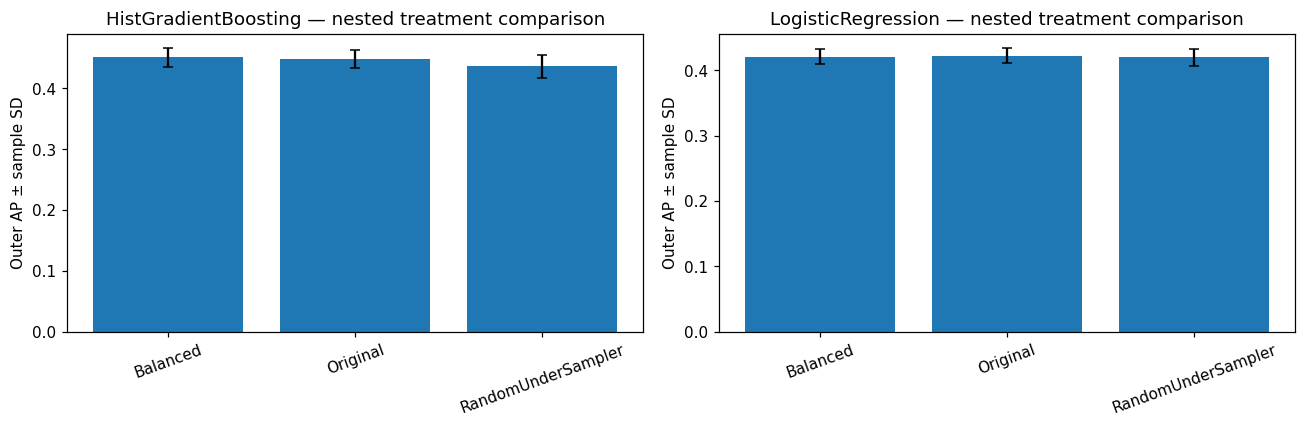

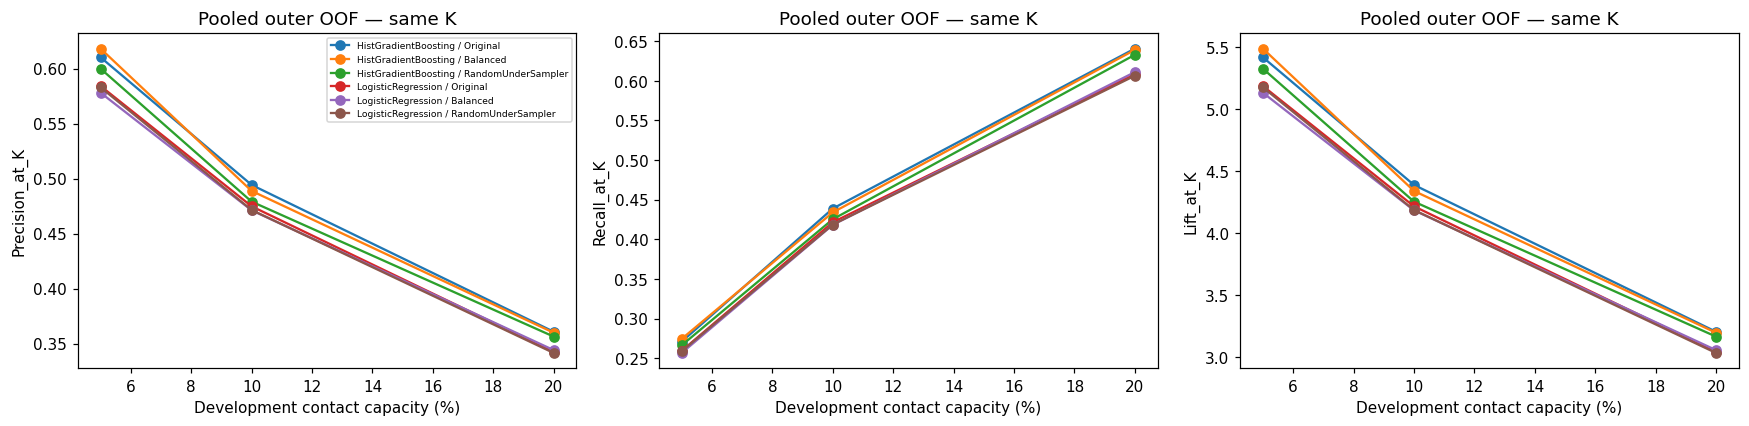

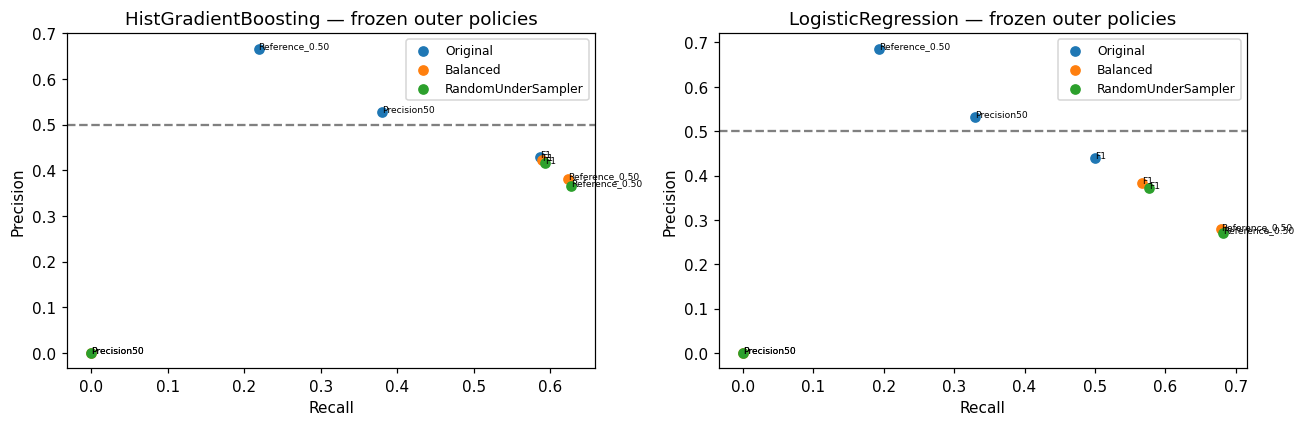

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,model in zip(axes,MODELS):
    d=ranking.loc[ranking.model.eq(model)];positions=np.arange(3)
    ax.bar(positions,d.AP_mean,yerr=d.AP_SD,capsize=3);ax.set_xticks(positions,d.treatment,rotation=20)
    ax.set(ylabel='Outer AP ± sample SD',title=model+' — nested treatment comparison')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,metric in zip(axes,['Precision_at_K','Recall_at_K','Lift_at_K']):
    for model in MODELS:
        for treatment in TREATMENTS:
            d=capacity.loc[capacity.model.eq(model)&capacity.treatment.eq(treatment)]
            ax.plot(d.fraction*100,d[metric],marker='o',label=model+' / '+treatment)
    ax.set(xlabel='Development contact capacity (%)',ylabel=metric,title='Pooled outer OOF — same K')
axes[0].legend(fontsize=6);plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,model in zip(axes,MODELS):
    d=pooled_policies.loc[pooled_policies.model.eq(model)]
    for treatment in TREATMENTS:
        z=d.loc[d.treatment.eq(treatment)];ax.scatter(z.Recall,z.Precision,label=treatment)
        for _,r in z.iterrows():ax.annotate(r.policy.replace('Training_',''),(r.Recall,r.Precision),fontsize=6)
    ax.axhline(.5,color='gray',ls='--');ax.set(xlabel='Recall',ylabel='Precision',title=model+' — frozen outer policies');ax.legend(fontsize=8)
plt.tight_layout();plt.show()



## 6. Audit, compute and provisional recommendations

Verify 1,130 current fits/prediction calls and 535 fitting-only resampler calls, input hashes and unchanged prior artifacts. Explain missing-dependency correction and pipeline wrapper adaptation, without modifying approved preprocessing. Standalone preprocessing tests run separately. No held-out rows, global fitting or validation resampling.

All 15 predictors remain Provisional. Feature timing, economic release/history snapshots, missing IDs/dates, prior full-data EDA, development-based model/grids/shortlist choice and dependent CV folds still limit claims. No financial/deployment optimality or significance without evidence. Review whether ranking/capture gains justify retaining treatments versus the existing threshold-only references. Approve any Phase 6 scope, capacity/cost assumptions, future calibration/range changes or optional synthetic scheme separately. No commit/push or next phase.


In [6]:
for name,digest in input_hashes.items():assert sha(PROJECT_DIR/name)==digest,name+' modified'
pd.testing.assert_frame_equal(dev,snapshot,check_exact=True)
assert all(a['status']=='PASS' for a in FIT_AUDIT+PRED_AUDIT+SAMPLING_AUDIT)
assert np.isfinite(capacity.select_dtypes('number').to_numpy()).all()
assert np.isfinite(ranking.select_dtypes('number').to_numpy()).all()
print('All 1,130 fits/prediction calls and 535 training-only sampler calls passed; sources unchanged.')
def mdtable(frame,index=False):
    t=frame.reset_index() if index else frame.copy()
    def fmt(v):return f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v).replace('|',' / ').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,t.columns))+' |','| '+' | '.join(['---']*len(t.columns))+' |']+['| '+' | '.join(fmt(v) for v in r)+' |' for r in t.itertuples(index=False,name=None)])
warning_text=mdtable(pd.DataFrame(WARNING_LOG)) if WARNING_LOG else 'None recorded across all 1,130 current-phase fits.'
elapsed=time.perf_counter()-started
ap_order=ranking.sort_values('AP_mean',ascending=False)
summary=f"""# Phase 5B-2 — Imbalance treatments and fair decision policies

## Provenance, scope and reuse

Started from latest fetched/merged GitHub main **{BASE_MAIN}** (Phase 5B-1 included); local branch fast-forwarded without creating a commit. Reviewed relevant Phase 2C–5B-1 code/notebooks/summaries, especially approved preprocessing, saved split and nested/threshold reports. Only HGB and LR are developed. No held-out evaluation, new model family, feature ablation, final policy selection or Phase 6.

Cleaned SHA-256 `{input_hashes['02_cleaned_dataset.csv']}` binds exact data/row order to 03_split_indices.json. Saved positions are unique/disjoint/exhaustive: 32,940 development and 8,236 held-out. Parser skips held-out rows; only development rows are materialized. Outer StratifiedKFold(5,shuffle=True,random_state=42) and validation-position hash `{outer_hash}` match Phase 5A/5B-1. Inner/threshold-OOF five-fold partitions are identical across treatments within each outer training set. Each outer validation cohort retains its original prevalence and 6,588 records.

Original no-treatment training-only hyperparameter selections from Phase 5A are reused, not chosen from outer scores; selected pipelines and threshold OOF values are regenerated. All 30 no-treatment policy-fold scores, thresholds and positive counts reproduce Phase 5B-1. Both new treatments run fresh complete inner searches on the exact approved grids. Effective selection budget is identical per model/treatment: LR 3 and HGB 16 candidates × five inner folds × five outer folds. No sampler-ratio/weight grid is added. Reusing archived original-arm grid decisions saves 475 duplicate candidate-fold fits, not a smaller baseline tuning budget. Current work executes 1,130 fits: 950 new inner candidate-fold fits +150 threshold-OOF fits +30 selected outer-training refits. Fully rerunning the archived original grid would have required 1,605 fits; no grid was reduced or expanded based on results.

## Treatment and model configurations

- Original: class_weight=None, sampler passthrough; exact Phase 5A per-fold parameter choices and Phase 5B-1 threshold procedure.
- Balanced: class_weight='balanced', no sampling. Each classifier derives class weights from its own fitting labels, not global development prevalence. Preprocessing is unweighted and matches the other arms.
- RandomUnderSampler: sampling_strategy='auto' (binary 1:1 balancing), replacement=False, random_state=42, classifier class_weight=None. Never combined with balanced class weights. Majority information is deliberately discarded within fitting folds; validation prevalence is never changed.

All classifiers use seed=42. LR: C=[0.1,1,10], lbfgs/default L2, max_iter=1000. HGB: learning_rate=[0.05,0.1], max_iter=[100,200], max_leaf_nodes=[15,31], l2_regularization=[0,1], early_stopping=False, categorical_features=None. Only inner AP selects each new treatment's configuration; outer scores do not select hyperparameters. Fixed grids/budgets and original raw covariates/folds are consistent across arms.

## Imbalanced-learn compatibility and sampling order

Validated imbalanced-learn {imblearn.__version__} with sklearn {sklearn.__version__}. This environment initially lacked imbalanced-learn; installed it and its required sklearn-compat dependency in a scratch dependency directory, leaving project files unchanged. The first dependency smoke test identified missing sklearn_compat after a no-dependencies install; installing sklearn-compat resolved it before experiments. Colab install instructions are in the notebook; no approved module is overwritten.

Imbalanced-learn rejects a nested sklearn Pipeline as an intermediate step. The experiment therefore takes the fresh, unfitted ColumnTransformer from `make_preprocessor(name).named_steps['preprocessor']` and places that exact approved object in an imbalanced-learn Pipeline. This removes only the redundant outer wrapper; it does not reimplement or change encoding/scaling/recency logic. Every arm uses this same adapter.

Order: approved preprocessing fit/transform on **all current fitting-fold rows** → stateless finite guard → training-only sampler (or passthrough) → classifier. Thus one-hot categories, ordinary scaling and available-only recency statistics are learned from original fitting rows before any row deletion, consistently across arms. Random selection then retains entire transformed rows, preserving categorical/recency relationships. It does not synthesize values or interpolate dummies. Every sampler call asserts original/retained row mapping, target alignment, unique selected positions and exactly equal retained binary class counts. At predict time imbalanced-learn skips the sampler; audit logs assert no sampler calls or sample-state changes occur and validation predictions retain full cohort size.

## Proper hyperparameter and threshold selection

For each outer fold, new treatment grids use GridSearchCV, scoring returning named AP from positive predict_proba, refit='AP', n_jobs=1, error_score='raise', only outer-training rows. Winners refit on outer training, never complete development. Selected-model training-side OOF probabilities then fit thresholds, with fresh full pipelines (and training-only sampling) in five subfolds. Hyperparameters use that entire outer-training partition's previous inner scoring, so training-side OOF is conditional on a training-selected configuration and is not claimed as independent performance; it serves threshold fitting only. The untouched outer layer evaluates both choices.

Threshold grid unchanged from Phase 5B-1: {GRID.tolist()}. Three policies: .50 reference; training-OOF F1 maximum (ties higher threshold); maximum recall with empirical precision >=50% and positive volume (ties precision, then higher threshold). The 50% target is illustrative research, not bank policy. If none qualifies **within this grid**, record none feasible and abstain with zero contacts, not a guarantee of precision. This does not prove no threshold outside the grid can qualify. No grid expansion after seeing outcomes. Probability shifts from weighting/sampling can move useful thresholds outside this range; calibration/prior correction is not silently introduced.

Thresholds freeze before outer predictions/labels are used for evaluation. AP/ROC-AUC remain identical across decision policies for the same probability predictions; only treatment/model training can change ranking. No outer-label threshold optimization or global preprocessing.

## Selected hyperparameters

{mdtable(selections)}

All new-treatment inner candidates (selection scores only, not outer performance):

{mdtable(pd.DataFrame(candidate_rows))}

## Individual outer-fold policy metrics

{mdtable(policy_results)}

Five-fold mean ± sample SD (ddof=1); contact counts are per-cohort averages and positive_rate a fraction:

{mdtable(comparison,index=True)}

Ranking comparison, invariant to threshold:

{mdtable(ranking)}

Pooled outer-policy diagnostics (not a substitute for mean-fold values):

{mdtable(pooled_policies)}

## Threshold stability and grid-feasibility

{mdtable(thresholds)}

{mdtable(stability)}

{mdtable(infeasible)}

A training constraint does not guarantee outer precision; zero-contact abstentions are reported with precision/recall/F1=0 under zero_division=0. Treat infeasible-grid cases separately from evidence that a treatment cannot ever meet a precision goal. Resampling/weighting changes the fitted score distribution and can change which fixed threshold is appropriate. It does not automatically improve the ranking objective.

## Business targeting at identical capacities

All ranks use nested outer-validation probabilities, never in-sample refit scores. Top 5/10/20% capacities are fixed in advance. K=ceil(fraction*N); descending score with saved-row-position ties independent of outcomes. Precision@K=captured/K; Recall@K=captured/actual positives; Lift@K=precision/cohort prevalence. Every model/treatment uses identical K for a given cohort. capture_minus_original_HGB is the additional historical subscribers versus the original HGB at the same pooled K, not a causal effect.

{mdtable(capacity)}

Fold-local mean/sample SD (less sensitive to cross-model probability calibration shifts across outer folds):

{mdtable(local_summary)}

Pooled scores combine five separately fitted models with potentially different calibration and overlapping training sets. Ceil rounding changes summed fold-local capacities slightly versus pooled. No call costs, incremental revenue, causal outreach response or actual bank budget is known; no financial optimum follows.

## Sampler audit and computational evidence

{mdtable(fit_summary)}

Training-only sampling counts, min/max across fitting calls with the same group:

{mdtable(sampling_summary)}

{mdtable(cost)}

{mdtable(cost_summary,index=True)}

Elapsed through experiments/plots {elapsed:.2f}s. Versions: sklearn {sklearn.__version__}, imbalanced-learn {imblearn.__version__}, pandas {pd.__version__}, NumPy {np.__version__}. Native threads limited to one; RF is not searched. Runtime includes audit/threshold selection; saved baseline selections make its current cost lower without reducing its original selection budget. Hosted Colab was not directly exercised.

## Technical validation

All 1,130 fresh fitting pipelines and corresponding prediction calls passed; all 535 sampler calls were fitting-only. Fit indices match current inner/OOF training partitions or the selected outer-training refit, disjoint from outer validation and held-out indices. Every prediction is disjoint from its estimator's fitting rows and must match the authorized training-side/outer cohort. Entire development fitting is impossible under allowed partition keys. OneHotEncoder vocabulary equals raw fitting-row levels; LR mean/variance/scale/sample count equals fitting data before sampling; ConditionalRecencyScaler only uses available fitting observations, placeholder standardized values remain zero and availability stays unscaled. HGB numeric/recency values exactly match validation input and 999 never appears. Finite matrices/probabilities/metrics, class mapping [0,1], unchanged fitted state on predict, no validation resampling, unchanged datasets/split/preprocessing and old results were asserted. Threshold selection determinism/no-feasible fallback is tested; original baseline replication provides an additional compatibility check. Existing preprocessing unit tests are run separately.

Warnings/errors during model experiments:

{warning_text}

## Is imbalance treatment worth retaining? Provisional Phase 6 discussion

Use nested AP/ROC and equal-capacity capture to judge ranking improvements, distinct from recall increases caused only by moving probability thresholds. Compare every treatment against the already-evaluated unweighted F1/precision policies, not just .50. A weighted/resampled .50 rule may approximate a lower threshold without increasing AP or subscriber capture. High recall alone, or a best point on these outer plots, is not a policy-selection justification. Do not assume complex imbalance treatment must help. Current AP ordering is {', '.join(ap_order.model+' / '+ap_order.treatment)}; statistical significance was not tested.

Retain original HGB and LR as references; any treatment shortlist must be justified by the actual ranking/capture trade-offs and selection uncertainty in these tables, not default preference for balance. No final deployment policy or feature ablation is chosen. Prior whole-development model/grid/shortlist exploration and family selection on outer means remain limitations despite correct within-experiment nesting.

Optional SMOTENC is **deferred, not implemented**. A defensible mixed-type design would resample training-only numerical and categorical representations before final one-hot encoding, mark categorical fields (including the binary availability flag), learn any distance-related scaling only within fitting folds, and preserve recency-availability consistency and legitimate count domains in synthetic records. Vanilla mixed-type interpolation can still create nonzero unavailable recency or fractional counts; extra constraints/validation and approval are needed. Ordinary SMOTE on the full one-hot matrix is not an acceptable substitute. No synthetic records or new encoding strategy were introduced.

All 15 predictors remain Provisional: {', '.join(FEATURES)}. Confirm campaign-start customer/status snapshots, historical contact/recency cutoff/reference date, economic publication/revision vintages and target window. Missing customer IDs/timestamps allow repeated-client/temporal overlap; prior full-data EDA also limits claims. Preprocessing/sampling isolation does not eliminate feature-timing leakage or certify future-campaign/unseen-client generalization.

Team decisions for Phase 6: which model/treatment and decision-objective candidates to retain; whether a wider predeclared threshold range or calibration is justified (not changed here); bank capacity, illustrative precision target and error/benefit assumptions; uncertainty analysis; and acceptable timing/client validation evidence. No final feature ablation, held-out evaluation, Phase 6, commit or push occurred.

Deliverables: executed 08_imbalance_treatment.ipynb and this 08_imbalance_treatment_summary.md in the repository. Stop pending review.
"""
completion_review = "## Completion review and recommendations\n\nObserved outer-CV ranking (mean AP ± sample SD):\n\n| Model | Original | Balanced | RandomUnderSampler |\n| --- | --- | --- | --- |\n| HGB | 0.448145 ± 0.014219 | 0.450883 ± 0.015341 | 0.436259 ± 0.019079 |\n| Logistic Regression | 0.422429 ± 0.011606 | 0.420526 ± 0.011461 | 0.419671 ± 0.012471 |\n\nBalanced HGB increases mean AP by 0.002738 and ROC-AUC by 0.000587 versus original HGB. AP is higher in four outer folds and lower in one; five dependent folds do not establish statistical significance. At pooled top 5%, 10%, 20% capacities (1,647 / 3,294 / 6,588 contacts), original HGB captures 1,005 / 1,628 / 2,377 historical subscribers; balanced HGB captures 1,018 / 1,610 / 2,371: **+13 / −18 / −6**, respectively. Its top-5% precision is 61.81% versus 61.02%. Fold-local mean capture similarly changes from 202 to 205 at 5%, 325.4 to 322 at 10%, and remains 474.2 at 20%; rounded fold-local capacities differ slightly from pooled capacities. This is a small, capacity-dependent trade-off, not a consistent targeting improvement.\n\nHGB undersampling lowers AP by 0.011886 and loses 17 / 50 / 29 subscribers at the same pooled capacities. Both LR treatments lower AP; balanced LR gains 10 subscribers at 20% versus original LR but loses capture at 5% and 10%. No treatment consistently beats original HGB across the three capacities.\n\nThreshold effects must be judged against the existing threshold-only strategies. At .50, balanced HGB recall rises from 0.218813 to 0.623550, while precision falls from 0.667746 to 0.381950 and contact volume rises from 3.70% to 18.40%. Original HGB's training-F1 rule already achieves recall 0.586634 and F1 0.495146 at 15.43% contact volume; balanced HGB's grid-F1 rule gives recall 0.589328, lower F1 0.491954 and 15.73% volume. Undersampled HGB F1 is 0.489511. Original LR's F1-selected policy also exceeds both LR treatment policies (0.467336 versus 0.457502 / 0.451457). Higher recall at .50 alone therefore does not demonstrate useful imbalance-treatment gains.\n\nAll four new model/treatment arms select F1 threshold .60 in all five folds, the upper grid boundary. None finds a precision-constrained candidate within .10–.60 in any fold, so their constrained policies explicitly abstain. Their zero precision/recall/F1 denotes zero contacts under the fallback, not a satisfied 50% constraint. The original arms select .35 for that constraint and obtain mean outer precision 0.527200 (HGB) / 0.531257 (LR). **Grid-limited infeasibility does not rule out higher thresholds**; the F1 maxima are also grid-limited. A wider prespecified range or calibration would require a new training-only selection design and team approval, not post-hoc adjustment here.\n\nEvidence-based shortlist for discussion: retain **original HGB** as the main reference and **original LR** as the simpler benchmark; retain **balanced HGB only as a secondary research candidate**, especially if 5% capacity matters. Deprioritize the tested undersampling arms and balanced LR because they show no consistent advantage over threshold-only references. These are research recommendations, not final model or deployment-policy choices. SMOTENC remains deferred. No causal or financial benefit, statistical significance, or unseen-campaign performance is established.\n\nSeparate local technical verification: `python -m unittest discover -s tests -v` passed all **4** existing preprocessing tests. All 1,130 current fits, 1,130 prediction calls and 535 training-only sampler calls passed runtime audits with no model warnings. No previous tracked artifact changed; datasets, saved indices and approved preprocessing.py are preserved. Notebook code executed locally; its nbformat schema, all six code-cell syntax checks, six execution records and three saved figures passed validation. Every pre-existing tracked file was also compared byte-for-byte against approved HEAD and matched. Hosted Colab execution was not directly tested. The Colab setup lists every required input, including the archived Phase 5A notebook used to verify parameter provenance. No held-out records were parsed for fitting/evaluation; no final ablation, Phase 6, commit or push occurred.\n\n"
_summary_title, _summary_rest = summary.split("\n", 1)
summary = _summary_title + "\n\n" + completion_review + _summary_rest.lstrip("\n")
(PROJECT_DIR/'08_imbalance_treatment_summary.md').write_text(summary)
print('Saved Phase 5B-2 report; no commit/push or Phase 6.')


All 1,130 fits/prediction calls and 535 training-only sampler calls passed; sources unchanged.
Saved Phase 5B-2 report; no commit/push or Phase 6.


## Completion review and recommendations

Observed outer-CV ranking (mean AP ± sample SD):

| Model | Original | Balanced | RandomUnderSampler |
| --- | --- | --- | --- |
| HGB | 0.448145 ± 0.014219 | 0.450883 ± 0.015341 | 0.436259 ± 0.019079 |
| Logistic Regression | 0.422429 ± 0.011606 | 0.420526 ± 0.011461 | 0.419671 ± 0.012471 |

Balanced HGB increases mean AP by 0.002738 and ROC-AUC by 0.000587 versus original HGB. AP is higher in four outer folds and lower in one; five dependent folds do not establish statistical significance. At pooled top 5%, 10%, 20% capacities (1,647 / 3,294 / 6,588 contacts), original HGB captures 1,005 / 1,628 / 2,377 historical subscribers; balanced HGB captures 1,018 / 1,610 / 2,371: **+13 / −18 / −6**, respectively. Its top-5% precision is 61.81% versus 61.02%. Fold-local mean capture similarly changes from 202 to 205 at 5%, 325.4 to 322 at 10%, and remains 474.2 at 20%; rounded fold-local capacities differ slightly from pooled capacities. This is a small, capacity-dependent trade-off, not a consistent targeting improvement.

HGB undersampling lowers AP by 0.011886 and loses 17 / 50 / 29 subscribers at the same pooled capacities. Both LR treatments lower AP; balanced LR gains 10 subscribers at 20% versus original LR but loses capture at 5% and 10%. No treatment consistently beats original HGB across the three capacities.

Threshold effects must be judged against the existing threshold-only strategies. At .50, balanced HGB recall rises from 0.218813 to 0.623550, while precision falls from 0.667746 to 0.381950 and contact volume rises from 3.70% to 18.40%. Original HGB's training-F1 rule already achieves recall 0.586634 and F1 0.495146 at 15.43% contact volume; balanced HGB's grid-F1 rule gives recall 0.589328, lower F1 0.491954 and 15.73% volume. Undersampled HGB F1 is 0.489511. Original LR's F1-selected policy also exceeds both LR treatment policies (0.467336 versus 0.457502 / 0.451457). Higher recall at .50 alone therefore does not demonstrate useful imbalance-treatment gains.

All four new model/treatment arms select F1 threshold .60 in all five folds, the upper grid boundary. None finds a precision-constrained candidate within .10–.60 in any fold, so their constrained policies explicitly abstain. Their zero precision/recall/F1 denotes zero contacts under the fallback, not a satisfied 50% constraint. The original arms select .35 for that constraint and obtain mean outer precision 0.527200 (HGB) / 0.531257 (LR). **Grid-limited infeasibility does not rule out higher thresholds**; the F1 maxima are also grid-limited. A wider prespecified range or calibration would require a new training-only selection design and team approval, not post-hoc adjustment here.

Evidence-based shortlist for discussion: retain **original HGB** as the main reference and **original LR** as the simpler benchmark; retain **balanced HGB only as a secondary research candidate**, especially if 5% capacity matters. Deprioritize the tested undersampling arms and balanced LR because they show no consistent advantage over threshold-only references. These are research recommendations, not final model or deployment-policy choices. SMOTENC remains deferred. No causal or financial benefit, statistical significance, or unseen-campaign performance is established.

Separate local technical verification: `python -m unittest discover -s tests -v` passed all **4** existing preprocessing tests. All 1,130 current fits, 1,130 prediction calls and 535 training-only sampler calls passed runtime audits with no model warnings. No previous tracked artifact changed; datasets, saved indices and approved preprocessing.py are preserved. Notebook code executed locally; its nbformat schema, all six code-cell syntax checks, six execution records and three saved figures passed validation. Every pre-existing tracked file was also compared byte-for-byte against approved HEAD and matched. Hosted Colab execution was not directly tested. The Colab setup lists every required input, including the archived Phase 5A notebook used to verify parameter provenance. No held-out records were parsed for fitting/evaluation; no final ablation, Phase 6, commit or push occurred.

